In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
train_df = pd.read_csv("data/train.csv",encoding="utf-8")
test_df = pd.read_csv("data/test.csv",encoding="utf-8")

In [3]:
import os
print(os.getcwd())

C:\Users\Berkay\PycharmProjects\sandbox\titanic_comp


In [4]:
train_df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [5]:
train_df.count()

PassengerId    891
Survived       891
Pclass         891
Name           891
Sex            891
Age            714
SibSp          891
Parch          891
Ticket         891
Fare           891
Cabin          204
Embarked       889
dtype: int64

In [6]:
train_df.head(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
title_map = {
    "Mr": "Mr",
    "Miss": "Miss",
    "Mlle": "Miss",
    "Ms": "Miss",
    "Mrs": "Mrs",
    "Mme": "Mrs",
    "Master": "Master",
    "Rev": "Rare",
    "Dr": "Rare",
    "Col": "Rare",
    "Major": "Rare",
    "Don": "Rare",
    "Dona": "Rare",
    "Lady": "Rare",
    "Sir": "Rare",
    "Capt": "Rare",
    "the Countess": "Rare",
    "Jonkheer": "Rare",
}

In [8]:
def preprocess_df(df):

    df = df.copy()

    drop_cols = ["PassengerId","Name","Ticket",]

    #get title
    get_name = df["Name"].apply(lambda x: x.split(",")[1])
    get_title = get_name.apply(lambda x: x.split(".")[0])
    df["Title"] = get_title
    df["Title"] = df["Title"].str.strip().map(title_map)

    #get Cabin title
    cabin_list = df["Cabin"].astype(str).to_list()
    cabins = []
    for x in cabin_list:
        if str(x) == "nan":
            cabins.append("Unknown")
        else:
            cabins.append(x[0])
    df["Cabin_Title"] = cabins

    #Embarked
    df["Embarked"] = df["Embarked"].fillna("S") ##fill embarked na with S as its the most common one

    #Gender
    df["Sex"] = df["Sex"].map({"male":1, "female":0}) ## map sex col to 0 and 1

    #Ticket
    df['TicketCount'] = df.groupby('Ticket')['Ticket'].transform('count') ##counts how many people holding the same ticket
    df = df.drop(columns='Ticket') ##drops Ticket after

    #add features
    df["Family_size"] = df["SibSp"] + df["Parch"] + 1
    df["isAlone"] = df["Family_size"] == 1
    df["GirlWithParents"] = ((df["Parch"] > 0) & (df["Title"] == "Miss")).astype(int)

    df = pd.get_dummies(df, columns=['Embarked', 'Title'], drop_first=True, dtype=int) ##turn the columns into one hot

    return df


In [9]:
train_pro_df = preprocess_df(train_df)

In [10]:
train_df.groupby(["Sex","Embarked"]).count()

PassengerId  Survived  Pclass  Name  Age  SibSp  Parch  \
Sex    Embarked                                                           
female C                  73        73      73    73   61     73     73   
       Q                  36        36      36    36   12     36     36   
       S                 203       203     203   203  186    203    203   
male   C                  95        95      95    95   69     95     95   
       Q                  41        41      41    41   16     41     41   
       S                 441       441     441   441  368    441    441   

                 Ticket  Fare  Cabin  
Sex    Embarked                       
female C             73    73     37  
       Q             36    36      2  
       S            203   203     56  
male   C             95    95     32  
       Q             41    41      2  
       S            441   441     73

In [11]:
train_df.iloc[train_df["Embarked"].isna()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
61,62,1,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.0,B28,NaN
829,830,1,1,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,113572,80.0,B28,NaN


In [12]:
train_pro_df.isna().sum()

PassengerId          0
Survived             0
Pclass               0
Name                 0
Sex                  0
Age                177
SibSp                0
Parch                0
Fare                 0
Cabin              687
Cabin_Title          0
TicketCount          0
Family_size          0
isAlone              0
GirlWithParents      0
Embarked_Q           0
Embarked_S           0
Title_Miss           0
Title_Mr             0
Title_Mrs            0
Title_Rare           0
dtype: int64

In [13]:
res_cabin = train_pro_df.drop(["Cabin","Cabin_Title","Name","PassengerId"], axis=1)

In [14]:
res_cabin.head(5)

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,TicketCount,Family_size,isAlone,GirlWithParents,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,0,3,1,22.0,1,0,7.2500,1,2,False,0,0,1,0,1,0,0
1,1,1,0,38.0,1,0,71.2833,1,2,False,0,0,0,0,0,1,0
2,1,3,0,26.0,0,0,7.9250,1,1,True,0,0,1,1,0,0,0
3,1,1,0,35.0,1,0,53.1000,2,2,False,0,0,1,0,0,1,0
4,0,3,1,35.0,0,0,8.0500,1,1,True,0,0,1,0,1,0,0


In [15]:
from sklearn.preprocessing import StandardScaler

fare_scaler = StandardScaler()
res_cabin["Fare"] = fare_scaler.fit_transform(res_cabin[["Fare"]])

In [16]:
res_cabin.head(5)

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,TicketCount,Family_size,isAlone,GirlWithParents,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,0,3,1,22.0,1,0,-0.502445,1,2,False,0,0,1,0,1,0,0
1,1,1,0,38.0,1,0,0.786845,1,2,False,0,0,0,0,0,1,0
2,1,3,0,26.0,0,0,-0.488854,1,1,True,0,0,1,1,0,0,0
3,1,1,0,35.0,1,0,0.420730,2,2,False,0,0,1,0,0,1,0
4,0,3,1,35.0,0,0,-0.486337,1,1,True,0,0,1,0,1,0,0


In [17]:
res_cabin.isna().sum()

Survived             0
Pclass               0
Sex                  0
Age                177
SibSp                0
Parch                0
Fare                 0
TicketCount          0
Family_size          0
isAlone              0
GirlWithParents      0
Embarked_Q           0
Embarked_S           0
Title_Miss           0
Title_Mr             0
Title_Mrs            0
Title_Rare           0
dtype: int64

In [18]:
age_known = res_cabin[res_cabin["Age"].notna()]
age_missing = res_cabin[res_cabin["Age"].isna()]
age_X = age_known.drop(columns=["Age", "Survived"])
age_y = age_known["Age"]

In [31]:
age_X.columns

Index(['Pclass', 'Sex', 'SibSp', 'Parch', 'Fare', 'TicketCount', 'Family_size',
       'isAlone', 'GirlWithParents', 'Embarked_Q', 'Embarked_S', 'Title_Miss',
       'Title_Mr', 'Title_Mrs', 'Title_Rare', 'cluster'],
      dtype='str')

In [19]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(age_X, age_y, test_size=0.2, random_state=42)

In [20]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

model = RandomForestRegressor(n_estimators=500, random_state=42)
model.fit(X_train, y_train)

pred = model.predict(X_test)
print("Model MAE:", mean_absolute_error(y_test, pred))

# baseline: just guess the median age every time
print("Baseline MAE:", mean_absolute_error(y_test, [y_train.median()] * len(y_test)))

Model MAE: 8.307943586785258
Baseline MAE: 10.804195804195805


In [21]:
print(X_train.nunique()[X_train.nunique() <= 1])

Series([], dtype: int64)


In [22]:
from sklearn.ensemble import HistGradientBoostingRegressor
gb = HistGradientBoostingRegressor(random_state=42).fit(X_train, y_train)
print(mean_absolute_error(y_test, gb.predict(X_test)))

7.965204925337126


In [23]:
from sklearn.model_selection import cross_val_score
for name, m in [("RF", model), ("GB", gb)]:
    s = -cross_val_score(m, age_X, age_y, cv=5, scoring="neg_mean_absolute_error")
    print(name, s.mean().round(2))

RF 9.36
GB 9.0


In [24]:
gb.fit(age_X, age_y)
res_cabin.loc[res_cabin["Age"].isna(), "Age"] = gb.predict(age_missing.drop(columns=["Age", "Survived"]))

In [26]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

iners = []
sil_scores = []
data = age_X

r = range(2,40)
for i in r:
    model = KMeans(n_clusters=i)
    model.fit(data)
    iner = model.inertia_
    sil_score = silhouette_score(data, model.predict(data))
    sil_scores.append(sil_score)
    iners.append(iner)
    print(f"n_clusters:{i}, sil_score:{sil_score}, inertia:{iner}")

n_clusters:2, sil_score:0.4967288642022239, inertia:3960.0575087070392
n_clusters:3, sil_score:0.3667770619918018, inertia:2972.1570875141733
n_clusters:4, sil_score:0.3575639437014805, inertia:2562.559800460054
n_clusters:5, sil_score:0.32717816873449906, inertia:2304.421449321502
n_clusters:6, sil_score:0.3248013084236839, inertia:2194.715651868679
n_clusters:7, sil_score:0.3016216564817527, inertia:2081.8643826251864
n_clusters:8, sil_score:0.3008962898437101, inertia:1887.1122097974153
n_clusters:9, sil_score:0.3126664670920239, inertia:1731.6019034654266
n_clusters:10, sil_score:0.317051738051427, inertia:1715.9068096866201
n_clusters:11, sil_score:0.3277612269163101, inertia:1601.8886244749237
n_clusters:12, sil_score:0.37075126412219833, inertia:1371.0904542362994
n_clusters:13, sil_score:0.3281697625356527, inertia:1462.579997268068
n_clusters:14, sil_score:0.38858594543205466, inertia:1186.63829039718
n_clusters:15, sil_score:0.3881897744379117, inertia:1130.8615340007264
n_cl

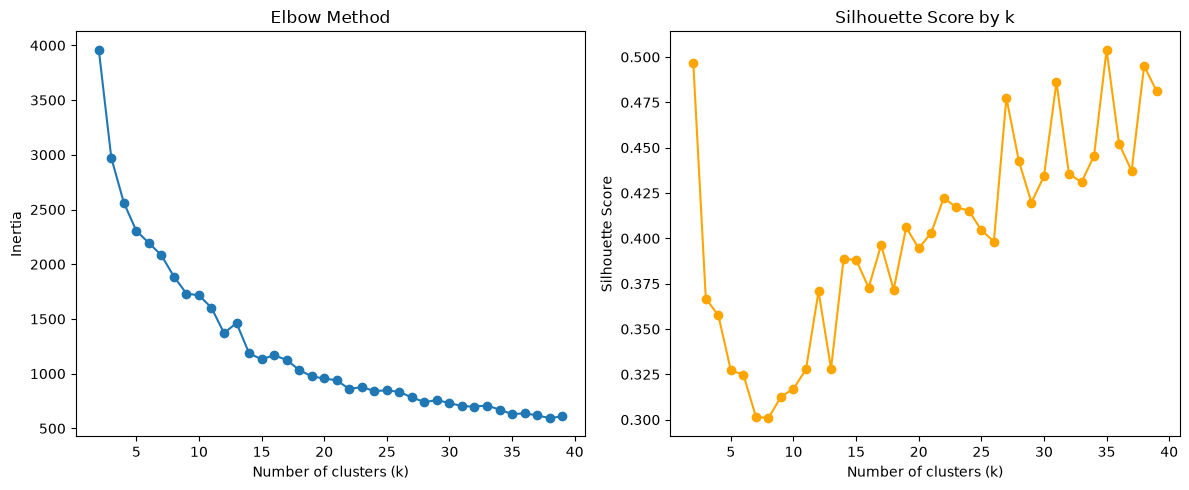

In [27]:
import matplotlib.pyplot as plt

k_range = r

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(k_range, iners, marker="o")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow Method")

axes[1].plot(k_range, sil_scores, marker="o", color="orange")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Score by k")

plt.tight_layout()
plt.show()

In [34]:
for x in range(1,20):
    k_best = KMeans(n_clusters=x)
    clusters = k_best.fit_predict(res_cabin[['Pclass', 'Sex', 'SibSp', 'Parch', 'Fare', 'TicketCount', 'Family_size',
       'isAlone', 'GirlWithParents', 'Embarked_Q', 'Embarked_S', 'Title_Miss',
       'Title_Mr', 'Title_Mrs', 'Title_Rare']])
    res_cabin["cluster"] = clusters

    age_stats = res_cabin.groupby("cluster")["Age"].agg(["mean", "std", "var", "count"])
    print(age_stats)

              mean        std         var  count
cluster                                         
0        29.609221  13.711939  188.017276    891
              mean        std         var  count
cluster                                         
0        30.897843  12.959335  167.944371    809
1        16.895860  14.503860  210.361965     82
              mean        std         var  count
cluster                                         
0        31.755304  11.933287  142.403342    542
1        15.865094  14.507147  210.457317     59
2        28.394484  14.883549  221.520028    290
              mean        std         var  count
cluster                                         
0        33.211052  12.863707  165.474947    100
1        26.044771  14.817127  219.547256    219
2        32.003629  11.905582  141.742887    514
3        15.638630  14.528269  211.070597     58
              mean        std         var  count
cluster                                         
0        40.128243  